# Bài 12 · Embedding câu và tìm kiếm ngữ nghĩa

**Thời lượng gợi ý:** 210 phút · **Cần:** Bài 2, Bài 9 · **Cần Internet** lần đầu (~0,5 GB) · GPU không bắt buộc

## Mục tiêu

1. Phát biểu bài toán **truy hồi thông tin** và tự cài **Recall@k, MRR, nDCG** để đánh giá.
2. Cài đặt **BM25** từ đầu và hiểu vì sao nó vẫn là baseline rất mạnh.
3. Dùng **mô hình embedding câu** (dense retrieval) với đúng tiền tố, gộp trung bình, chuẩn hóa.
4. **Hợp nhất** BM25 và dense bằng *Reciprocal Rank Fusion* (tìm kiếm lai).
5. Phân tích: cách nào thắng ở loại truy vấn nào; ảnh hưởng của **tách từ**, **bỏ dấu**, **tiền tố**.
6. Hiểu chiến lược **chia đoạn (chunking)** và chỉ mục vector ở quy mô lớn.

> Đây là nền tảng của **RAG** ở Bài 13: muốn LLM trả lời đúng theo tài liệu của bạn, trước hết phải tìm đúng đoạn tài liệu.

In [1]:
import sys, pathlib

ROOT = pathlib.Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")

import os
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")

import inspect, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import transformers
transformers.logging.set_verbosity_error()

from nlpvi import load_faq, segment, strip_accents, set_seed
from nlpvi.retrieval import (BM25, Embedder, search_tokens, rank_from_scores, rrf,
                             metrics_for, evaluate_rankings)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
set_seed(42)
docs, queries = load_faq()
doc_ids = [d["id"] for d in docs]
id2idx = {d: i for i, d in enumerate(doc_ids)}
doc_texts = [f"{d['title']}. {d['text']}" for d in docs]
gold = [[id2idx[g] for g in q["gold"]] for q in queries]
q_texts = [q["q"] for q in queries]
print(f"{len(docs)} đoạn tài liệu (FAQ của một cửa hàng hư cấu), {len(queries)} truy vấn có đáp án")
print("Ví dụ tài liệu:", doc_texts[0][:150], "...")
print("Ví dụ truy vấn:", q_texts[0], "→ đáp án:", queries[0]["gold"])

24 đoạn tài liệu (FAQ của một cửa hàng hư cấu), 33 truy vấn có đáp án
Ví dụ tài liệu: Đổi trả trong 7 ngày. Khách hàng được đổi hoặc trả sản phẩm trong vòng 7 ngày kể từ ngày nhận hàng nếu sản phẩm còn nguyên tem mác và hóa đơn. Sản phẩ ...
Ví dụ truy vấn: Mua hàng xong muốn trả lại thì có bao nhiêu ngày? → đáp án: ['d01']


## 1. Bài toán và độ đo

**Truy hồi**: cho một truy vấn và một kho tài liệu, xếp hạng tài liệu theo mức liên quan. Ta quan tâm các độ đo sau (với $k$ thường là 1, 3, 5, 10):

| Độ đo | Ý nghĩa |
|---|---|
| **Hit@k** (Success@k) | có *ít nhất một* tài liệu đúng trong top-k không? |
| **Recall@k** | trong các tài liệu đúng, bao nhiêu phần nằm trong top-k? |
| **MRR** | trung bình của $1/\text{hạng của tài liệu đúng đầu tiên}$ |
| **nDCG@k** | thưởng cho tài liệu đúng ở **hạng cao**; giảm dần theo $1/\log_2(\text{hạng}+1)$ |

Ta đã cài sẵn các hàm này trong `nlpvi/retrieval.py`. Hãy kiểm tra trên một ví dụ tay trước khi tin chúng:

In [2]:
# 5 tài liệu; đúng là tài liệu 2 và 4. Hệ thống xếp hạng: 0, 2, 1, 4, 3.
rk = [0, 2, 1, 4, 3]
print(metrics_for(rk, gold=[2, 4], ks=(1, 3, 5)))
print("Kiểm tay: hạng của tài liệu đúng đầu tiên = 2 → MRR = 1/2 =", 1 / 2,
      "| Recall@3 = 1/2 (chỉ thấy tài liệu 2) =", 1 / 2, "| Hit@1 = 0")

{'hit@1': 0.0, 'recall@1': 0.0, 'hit@3': 1.0, 'recall@3': 0.5, 'hit@5': 1.0, 'recall@5': 1.0, 'mrr': 0.5, 'ndcg@10': 0.6509209298071326}
Kiểm tay: hạng của tài liệu đúng đầu tiên = 2 → MRR = 1/2 = 0.5 | Recall@3 = 1/2 (chỉ thấy tài liệu 2) = 0.5 | Hit@1 = 0


## 2. Baseline 1: BM25

**BM25** là phiên bản cải tiến của TF-IDF cho xếp hạng: nó (a) **bão hòa** theo tần suất từ (xuất hiện 10 lần không "tốt hơn" 5 lần nhiều đến vậy) và (b) **chuẩn hóa độ dài** tài liệu:

$$\text{score}(q,d)=\sum_{t\in q}\text{idf}(t)\cdot\frac{\text{tf}(t,d)\,(k_1+1)}{\text{tf}(t,d)+k_1\,(1-b+b\,|d|/\text{avgdl})}$$

Mã nguồn đầy đủ (chỉ khoảng 25 dòng) — hãy đọc:

In [3]:
print(inspect.getsource(BM25))

class BM25:
    """Okapi BM25 cài đặt thuần Python.

    score(q, d) = Σ_t idf(t) · tf(t,d)·(k1+1) / (tf(t,d) + k1·(1 − b + b·|d|/avgdl))
    """

    def __init__(self, docs_tokens, k1: float = 1.5, b: float = 0.75):
        self.k1, self.b = k1, b
        self.tf = [Counter(d) for d in docs_tokens]
        self.dl = np.array([len(d) for d in docs_tokens], dtype=float)
        self.avgdl = self.dl.mean()
        df = Counter(t for d in self.tf for t in d)
        n = len(docs_tokens)
        self.idf = {t: math.log(1 + (n - c + 0.5) / (c + 0.5)) for t, c in df.items()}

    def scores(self, q_tokens):
        out = np.zeros(len(self.tf))
        for t in set(q_tokens):
            if t not in self.idf:
                continue
            for i, tf in enumerate(self.tf):
                f = tf.get(t, 0)
                if f:
                    out[i] += self.idf[t] * f * (self.k1 + 1) / (f + self.k1 * (1 - self.b + self.b * self.dl[i] / self.avgdl))
        return out



In [4]:
def xep_hang_bm25(word_level=True, strip=False):
    prep = (lambda t: strip_accents(t)) if strip else (lambda t: t)
    bm = BM25([search_tokens(prep(t), word_level) for t in doc_texts])
    return [rank_from_scores(bm.scores(search_tokens(prep(q), word_level))) for q in q_texts]

def tom_tat(rankings):
    m, _ = evaluate_rankings(rankings, gold)
    return {k: round(v, 3) for k, v in m.items()}

rows = {"BM25 (âm tiết)": tom_tat(xep_hang_bm25(word_level=False)),
        "BM25 (từ ghép)": tom_tat(xep_hang_bm25(word_level=True))}
pd.DataFrame(rows).T

,hit@1,recall@1,hit@3,recall@3,hit@5,recall@5,mrr,ndcg@10
BM25 (âm tiết),0.788,0.758,0.939,0.924,0.939,0.924,0.864,0.871
BM25 (từ ghép),0.909,0.879,0.909,0.894,0.939,0.939,0.920,0.915


So sánh hai dòng: **ghép từ** nâng Hit@1 của BM25 từ ≈0,79 lên ≈0,91 — chênh 4/33 truy vấn, đáng kể. Lý do: khi tách theo âm tiết, các âm tiết phổ biến như "trả" (đổi *trả*, *trả* góp, hàng *trả* về) khớp lẫn lộn giữa các tài liệu; khi ghép từ, "trả_góp" hay "đổi_trả" là đơn vị riêng. Bước tiền xử lý ở Bài 1 có tác động thật tới chất lượng tìm kiếm.

## 3. Dense retrieval: embedding câu

Thay vì khớp *chữ*, ta khớp *nghĩa*: mã hóa truy vấn và tài liệu thành vector, rồi xếp hạng theo **cosine**. Mô hình cần được huấn luyện **riêng** cho việc này (học tương phản trên hàng trăm triệu cặp văn bản) — không phải PhoBERT thô (Bài 9 đã thấy cosine của nó co cụm).

Ta dùng **`intfloat/multilingual-e5-small`** (giấy phép MIT, 118 triệu tham số, hỗ trợ tiếng Việt). Quy ước của họ E5, **bắt buộc**:

- thêm tiền tố **`query: `** vào truy vấn và **`passage: `** vào tài liệu;
- gộp **trung bình** các vector token (có mặt nạ), rồi **chuẩn hóa L2** (để cosine = tích vô hướng).

In [5]:
print(inspect.getsource(Embedder.encode))

    def encode(self, texts, kind="passage", batch_size=32):
        torch = self.torch
        prefix = self.qp if kind == "query" else self.pp
        texts = [prefix + (segment(t) if self.seg else t) for t in texts]
        out = []
        with torch.no_grad():
            for i in range(0, len(texts), batch_size):
                enc = self.tok(texts[i:i + batch_size], padding=True, truncation=True,
                               max_length=self.max_length, return_tensors="pt").to(self.device)
                h = self.model(**enc).last_hidden_state
                m = enc["attention_mask"].unsqueeze(-1).to(h.dtype)
                v = (h * m).sum(1) / m.sum(1)
                out.append(torch.nn.functional.normalize(v, dim=-1).float().cpu())
        return torch.cat(out).numpy()



In [6]:
t0 = time.time()
e5 = Embedder("intfloat/multilingual-e5-small", query_prefix="query: ", passage_prefix="passage: ")
print(f"Nạp mô hình: {time.time() - t0:.1f}s trên {e5.device}")
D = e5.encode(doc_texts, "passage")
Q = e5.encode(q_texts, "query")
print("Ma trận tài liệu:", D.shape, "| ma trận truy vấn:", Q.shape, "| ‖vector‖ =", np.linalg.norm(D[0]).round(3))

def xep_hang_dense(Q, D):
    S = Q @ D.T
    return [rank_from_scores(s) for s in S], S

rk_e5, S_e5 = xep_hang_dense(Q, D)
rows["multilingual-e5-small"] = tom_tat(rk_e5)
pd.DataFrame(rows).T

Nạp mô hình: 15.5s trên cuda


Ma trận tài liệu: (24, 384) | ma trận truy vấn: (33, 384) | ‖vector‖ = 1.0


,hit@1,recall@1,hit@3,recall@3,hit@5,recall@5,mrr,ndcg@10
BM25 (âm tiết),0.788,0.758,0.939,0.924,0.939,0.924,0.864,0.871
BM25 (từ ghép),0.909,0.879,0.909,0.894,0.939,0.939,0.920,0.915
multilingual-e5-small,0.879,0.848,0.970,0.955,0.970,0.955,0.923,0.936


### Đối chiếu từng truy vấn

Ta nhìn cả **bức tranh định tính**: truy vấn nào dense làm tốt mà BM25 hỏng, và ngược lại?

In [7]:
rk_bm = xep_hang_bm25(word_level=True)

def hang_dau_tien(rk, g):
    return next((p for p, d in enumerate(rk, 1) if d in set(g)), None)

bang = pd.DataFrame({
    "truy vấn": q_texts, "kiểu": [q["kieu"] for q in queries],
    "hạng BM25": [hang_dau_tien(r, g) for r, g in zip(rk_bm, gold)],
    "hạng e5": [hang_dau_tien(r, g) for r, g in zip(rk_e5, gold)]})
print("BM25 sai ở top-1 mà e5 đúng:\n")
x = bang[(bang["hạng BM25"] > 1) & (bang["hạng e5"] == 1)]
for _, r in x.head(6).iterrows():
    print(f"  [{r['kiểu']}] {r['truy vấn']}  (BM25 hạng {r['hạng BM25']}, e5 hạng 1)")
print("\ne5 sai ở top-1 mà BM25 đúng:\n")
y = bang[(bang["hạng e5"] > 1) & (bang["hạng BM25"] == 1)]
for _, r in y.head(6).iterrows():
    print(f"  [{r['kiểu']}] {r['truy vấn']}  (e5 hạng {r['hạng e5']}, BM25 hạng 1)")

BM25 sai ở top-1 mà e5 đúng:

  [diễn đạt lại] Gửi máy đi sửa thì bao lâu có lại?  (BM25 hạng 16, e5 hạng 1)
  [diễn đạt lại] Gọi hotline vào Chủ nhật được không?  (BM25 hạng 5, e5 hạng 1)

e5 sai ở top-1 mà BM25 đúng:

  [diễn đạt lại] Tôi bấm nhầm sản phẩm, có thể đổi sang món khác không?  (e5 hạng 3, BM25 hạng 1)
  [diễn đạt lại] Gửi hàng ra Đà Nẵng mất mấy ngày?  (e5 hạng 2, BM25 hạng 1)
  [diễn đạt lại] Thanh toán bằng Momo được không?  (e5 hạng 2, BM25 hạng 1)


## 4. Tìm kiếm lai: Reciprocal Rank Fusion

Hai hệ thống mắc lỗi *khác nhau* → kết hợp có thể tốt hơn cả hai. Điểm BM25 và cosine có thang đo khác nhau nên khó cộng trực tiếp; **RRF** tránh vấn đề đó bằng cách chỉ dùng **hạng**:

$$\text{RRF}(d)=\sum_{r\in\text{các hệ thống}}\frac{1}{k+\text{hạng}_r(d)},\qquad k=60$$

Không cần tinh chỉnh trọng số, rất bền, nên được dùng rộng rãi trong sản phẩm.

In [8]:
rk_hybrid = [rrf([a, b]) for a, b in zip(rk_bm, rk_e5)]
rows["Lai (RRF: BM25 + e5)"] = tom_tat(rk_hybrid)
df_ket_qua = pd.DataFrame(rows).T
df_ket_qua

,hit@1,recall@1,hit@3,recall@3,hit@5,recall@5,mrr,ndcg@10
BM25 (âm tiết),0.788,0.758,0.939,0.924,0.939,0.924,0.864,0.871
BM25 (từ ghép),0.909,0.879,0.909,0.894,0.939,0.939,0.920,0.915
multilingual-e5-small,0.879,0.848,0.970,0.955,0.970,0.955,0.923,0.936
Lai (RRF: BM25 + e5),0.939,0.909,0.939,0.924,0.939,0.939,0.947,0.955


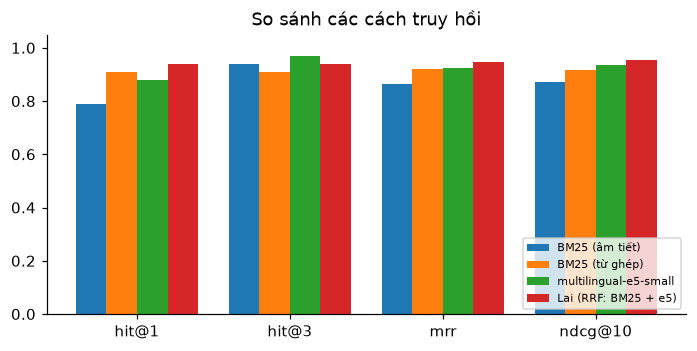

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 3.3))
chon = ["hit@1", "hit@3", "mrr", "ndcg@10"]
x = np.arange(len(chon)); w = 0.2
for i, (ten, r) in enumerate(df_ket_qua.iterrows()):
    ax.bar(x + (i - 1.5) * w, [r[c] for c in chon], w, label=ten)
ax.set_xticks(x); ax.set_xticklabels(chon); ax.set_ylim(0, 1.05); ax.legend(fontsize=7, loc="lower right")
ax.set_title("So sánh các cách truy hồi"); plt.show()

## 5. Phân tích theo loại truy vấn

Một con số trung bình che giấu nhiều điều. Ta tách kết quả theo `kiểu` truy vấn (cột `kieu` trong `faq_queries.json`):

In [10]:
def hit1_theo_kieu(rankings):
    _, per_q = evaluate_rankings(rankings, gold)
    return pd.Series([m["hit@1"] for m in per_q]).groupby([q["kieu"] for q in queries]).mean()

kieu_tbl = pd.DataFrame({"BM25": hit1_theo_kieu(rk_bm), "e5": hit1_theo_kieu(rk_e5), "Lai": hit1_theo_kieu(rk_hybrid)})
kieu_tbl["số truy vấn"] = pd.Series([q["kieu"] for q in queries]).value_counts()
kieu_tbl.round(2)

,BM25,e5,Lai,số truy vấn
chi tiết số,1.00,1.00,1.00,3
diễn đạt lại,0.87,0.83,0.91,23
nhiều đáp án,1.00,1.00,1.00,2
từ khóa trùng,1.00,1.00,1.00,5


Đọc bảng với sự thận trọng:

- Các nhóm "từ khóa trùng", "chi tiết số", "nhiều đáp án" đều đạt 100% ở cả ba hệ thống: truy vấn ở đây quá dễ để phân biệt chúng (và chỉ có 2–5 truy vấn mỗi nhóm).
- Toàn bộ sự khác biệt nằm ở nhóm **"diễn đạt lại"** (23/33 truy vấn): BM25 ≈0,87, e5 ≈0,83, lai ≈0,91. Kết quả này **không** theo kịch bản "dense luôn thắng ở diễn đạt lại". Lý do: truy vấn của kho FAQ này vẫn chia sẻ nhiều từ với tài liệu ("đổi", "trả", "ngày"), nên BM25 khỏe hơn ta tưởng; dense chỉ rõ ràng thắng ở vài truy vấn "xa chữ" như *"Gửi máy đi sửa thì bao lâu có lại?"* (BM25 xếp tài liệu đúng ở hạng 16).
- Với 33 truy vấn, **mỗi truy vấn là ~3 điểm phần trăm**. Chênh lệch 1–2 truy vấn là nhiễu. Đây là bài học về *thiết kế tập đánh giá*: muốn phân biệt các hệ thống bạn cần hàng trăm truy vấn thật, đa dạng, gồm cả ca khó.

## 6. Những chi tiết nhỏ quyết định chất lượng

### 6.1 Tiền tố `query:` / `passage:`

Bỏ tiền tố (một lỗi rất hay gặp khi tự ghép mô hình E5) có hại không? Ta đo cả **xếp hạng** lẫn **biên độ cosine** (khoảng cách giữa điểm của tài liệu đúng và tài liệu sai).

In [11]:
e5_khong_tien_to = Embedder("intfloat/multilingual-e5-small")      # không tiền tố
D0, Q0 = e5_khong_tien_to.encode(doc_texts, "passage"), e5_khong_tien_to.encode(q_texts, "query")
rk0, S0 = xep_hang_dense(Q0, D0)
display(pd.DataFrame({"e5 đúng tiền tố": tom_tat(rk_e5), "e5 KHÔNG tiền tố": tom_tat(rk0)}).T[["hit@1", "hit@3", "mrr", "ndcg@10"]])

def bien_do(S):
    """Cosine TB tới tài liệu đúng, tới tài liệu sai, và hiệu của chúng (độ tách)."""
    g = np.array([np.mean([S[i, j] for j in gold[i]]) for i in range(len(S))])
    ng = np.array([np.mean([S[i, j] for j in range(S.shape[1]) if j not in gold[i]]) for i in range(len(S))])
    return {"cos TB tài liệu đúng": g.mean(), "cos TB tài liệu sai": ng.mean(), "biên độ tách": (g - ng).mean()}

pd.DataFrame({"đúng tiền tố": bien_do(S_e5), "KHÔNG tiền tố": bien_do(S0)}).T.round(3)

,hit@1,hit@3,mrr,ndcg@10
e5 đúng tiền tố,0.879,0.97,0.923,0.936
e5 KHÔNG tiền tố,0.879,0.97,0.923,0.935


,cos TB tài liệu đúng,cos TB tài liệu sai,biên độ tách
đúng tiền tố,0.874,0.804,0.070
KHÔNG tiền tố,0.879,0.813,0.066


**Đọc kết quả.** Trên tập nhỏ này, bỏ tiền tố **không đổi gì đáng kể** (Hit@1 như nhau; biên độ tách ≈0,066 so với ≈0,070). Đừng suy ra "tiền tố vô nghĩa": tác giả mô hình yêu cầu chúng, và tác động thường lộ ra trên kho lớn hơn, truy vấn khó hơn hoặc khi gặp tài liệu dài. Quy tắc an toàn: **làm đúng theo thẻ mô hình**.

Có một quan sát thực tế quan trọng khác ở bảng biên độ: cosine của e5 nằm trong một dải hẹp — **ngay cả tài liệu sai cũng đạt cosine ≈0,80** (tài liệu đúng ≈0,87). Vì vậy **không dùng ngưỡng cosine tuyệt đối** kiểu "trên 0,7 là liên quan"; hãy dựa vào *hạng*, hoặc hiệu chuẩn ngưỡng trên dữ liệu của bạn (điều ta sẽ cần ở Bài 13 để quyết định khi nào hệ thống nên từ chối trả lời).

### 6.2 Bỏ dấu tiếng Việt

Người dùng gõ không dấu rất phổ biến. Các hệ thống chịu đựng điều đó thế nào? Ta bỏ dấu **cả truy vấn** (tài liệu giữ nguyên):

In [12]:
Q_nd = e5.encode([strip_accents(q) for q in q_texts], "query")
rk_e5_nd, _ = xep_hang_dense(Q_nd, D)

bm = BM25([search_tokens(t) for t in doc_texts])
rk_bm_nd = [rank_from_scores(bm.scores(search_tokens(strip_accents(q)))) for q in q_texts]      # tài liệu có dấu, truy vấn không dấu
rk_bm_nd2 = xep_hang_bm25(word_level=False, strip=True)                                            # bỏ dấu CẢ HAI phía

pd.DataFrame({
    "BM25 có dấu": tom_tat(rk_bm), "BM25: truy vấn không dấu, tài liệu có dấu": tom_tat(rk_bm_nd),
    "BM25: bỏ dấu cả hai phía": tom_tat(rk_bm_nd2),
    "e5 có dấu": tom_tat(rk_e5), "e5: truy vấn không dấu": tom_tat(rk_e5_nd)}).T[["hit@1", "hit@3", "mrr"]]

,hit@1,hit@3,mrr
BM25 có dấu,0.909,0.909,0.920
"BM25: truy vấn không dấu, tài liệu có dấu",0.152,0.333,0.306
BM25: bỏ dấu cả hai phía,0.788,0.848,0.847
e5 có dấu,0.879,0.970,0.923
e5: truy vấn không dấu,0.242,0.485,0.409


Kết quả khá mạnh và đáng chú ý:

1. **BM25** so khớp *chuỗi*: truy vấn không dấu so với tài liệu có dấu gần như **không khớp được gì** (Hit@1 ≈0,15). Chuẩn hóa *cả hai phía* cùng cách (bỏ dấu cả hai) cứu lại gần hết: ≈0,79, **bằng đúng** BM25-âm-tiết có dấu — tức không mất gì so với cách tách cùng mức. Nhưng không bằng BM25-từ-ghép có dấu (≈0,91) vì ghép từ cần dấu.
2. **Mô hình dense không tự động bền với văn bản không dấu**: Hit@1 sụt từ ≈0,88 xuống ≈0,24. Chuỗi không dấu nằm ngoài phân phối huấn luyện (nhớ lại ở Bài 9: số token tăng vọt) nên vector bị lệch.

Hệ quả thực tế: nếu người dùng của bạn hay gõ không dấu, cần một **bước khôi phục dấu**, hoặc lập chỉ mục BM25 song song cho dạng không dấu và đưa vào tìm kiếm lai. Đừng giả định "mô hình hiểu nghĩa" nghĩa là "mô hình bền với mọi kiểu viết".

### 6.3 Một mô hình embedding chuyên cho tiếng Việt

`bkai-foundation-models/vietnamese-bi-encoder` (Apache-2.0) là bi-encoder xây trên **PhoBERT**, nên cần **văn bản đã tách từ** và không dùng tiền tố. Ta thử so sánh:

Lưu ý khi đọc: với **33 truy vấn**, chênh lệch giữa các hệ thống trong bảng bên dưới chỉ là 1–3 truy vấn, nên **không** kết luận được hệ thống nào "tốt nhất".

In [13]:
try:
    bk = Embedder("bkai-foundation-models/vietnamese-bi-encoder", segment_input=True, max_length=256)
    rk_bk, _ = xep_hang_dense(bk.encode(q_texts, "query"), bk.encode(doc_texts, "passage"))
    rows["vietnamese-bi-encoder"] = tom_tat(rk_bk)
    rk_hybrid3 = [rrf([a, b, c]) for a, b, c in zip(rk_bm, rk_e5, rk_bk)]
    rows["Lai 3 nguồn (BM25+e5+bkai)"] = tom_tat(rk_hybrid3)
except Exception as e:
    print("Không nạp được mô hình bkai:", type(e).__name__, str(e)[:150])
pd.DataFrame(rows).T

,hit@1,recall@1,hit@3,recall@3,hit@5,recall@5,mrr,ndcg@10
BM25 (âm tiết),0.788,0.758,0.939,0.924,0.939,0.924,0.864,0.871
BM25 (từ ghép),0.909,0.879,0.909,0.894,0.939,0.939,0.920,0.915
multilingual-e5-small,0.879,0.848,0.970,0.955,0.970,0.955,0.923,0.936
Lai (RRF: BM25 + e5),0.939,0.909,0.939,0.924,0.939,0.939,0.947,0.955
vietnamese-bi-encoder,0.939,0.909,1.000,0.985,1.000,0.985,0.965,0.967
Lai 3 nguồn (BM25+e5+bkai),0.909,0.879,0.970,0.955,0.970,0.955,0.943,0.952


## 7. Chia đoạn (chunking) và quy mô

Kho FAQ của ta có các đoạn ngắn. Tài liệu thật (quy định, sách, trang web) dài hàng nghìn từ, trong khi mô hình embedding chỉ nhận tối đa vài trăm token và **một vector cho cả đoạn dài sẽ "pha loãng" ý**. Cách xử lý chuẩn: **chia tài liệu thành các đoạn (chunk)** rồi lập chỉ mục từng đoạn.

| Chiến lược | Ưu | Nhược |
|---|---|---|
| Cắt cố định theo số token/ký tự | đơn giản | cắt giữa câu/ý |
| **Cắt theo câu, gom đến ~N token, có chồng lấn** | giữ nguyên câu, chồng lấn tránh mất ngữ cảnh ở biên | cần bộ tách câu tốt |
| Cắt theo cấu trúc (tiêu đề, mục) | giữ ý nguyên vẹn | cần cấu trúc rõ |

Ví dụ tối giản: cắt theo câu, mỗi đoạn tối đa `max_tu` từ, chồng lấn 1 câu.

In [14]:
from nlpvi import split_sentences

def chia_doan(text, max_tu=40, chong_lan=1):
    cau = split_sentences(text)
    doan, cur = [], []
    for c in cau:
        if cur and sum(len(x.split()) for x in cur) + len(c.split()) > max_tu:
            doan.append(" ".join(cur))
            cur = cur[-chong_lan:] if chong_lan else []
        cur.append(c)
    if cur:
        doan.append(" ".join(cur))
    return doan

dai = " ".join(d["text"] for d in docs[:4])
for i, d in enumerate(chia_doan(dai)):
    print(f"[đoạn {i}] ({len(d.split())} từ) {d}")

[đoạn 0] (38 từ) Khách hàng được đổi hoặc trả sản phẩm trong vòng 7 ngày kể từ ngày nhận hàng nếu sản phẩm còn nguyên tem mác và hóa đơn. Sản phẩm giảm giá trên 50% không áp dụng đổi trả.
[đoạn 1] (38 từ) Sản phẩm giảm giá trên 50% không áp dụng đổi trả. Tiền hoàn lại được chuyển về phương thức thanh toán ban đầu trong 5 đến 7 ngày làm việc sau khi cửa hàng nhận được hàng trả.
[đoạn 2] (41 từ) Tiền hoàn lại được chuyển về phương thức thanh toán ban đầu trong 5 đến 7 ngày làm việc sau khi cửa hàng nhận được hàng trả. Với đơn thanh toán khi nhận hàng, tiền hoàn qua chuyển khoản ngân hàng.
[đoạn 3] (34 từ) Với đơn thanh toán khi nhận hàng, tiền hoàn qua chuyển khoản ngân hàng. Đơn hàng giao trong nội thành Hà Nội và Thành phố Hồ Chí Minh có phí vận chuyển 20.000 đồng.
[đoạn 4] (31 từ) Đơn hàng giao trong nội thành Hà Nội và Thành phố Hồ Chí Minh có phí vận chuyển 20.000 đồng. Đơn từ 500.000 đồng trở lên được miễn phí vận chuyển.
[đoạn 5] (26 từ) Đơn từ 500.000 đồng trở lên được miễn phí v

### Quy mô: vì sao cần chỉ mục vector?

Tìm kiếm *vét cạn* (so truy vấn với mọi vector) là một phép nhân ma trận: chính xác nhưng tốn $O(N\cdot d)$. Đo thử:

In [15]:
rng = np.random.default_rng(0)
for N in [10_000, 100_000, 1_000_000]:
    M = rng.standard_normal((N, 384)).astype(np.float32)
    M /= np.linalg.norm(M, axis=1, keepdims=True)
    q = M[0]
    t0 = time.time()
    for _ in range(3):
        top = np.argpartition(-(M @ q), 10)[:10]
    print(f"N = {N:>9,}: {(time.time() - t0) / 3 * 1000:7.1f} ms mỗi truy vấn, bộ nhớ {M.nbytes / 1e6:6.0f} MB")
    del M

N =    10,000:     0.9 ms mỗi truy vấn, bộ nhớ     15 MB


N =   100,000:     5.1 ms mỗi truy vấn, bộ nhớ    154 MB


N = 1,000,000:    50.5 ms mỗi truy vấn, bộ nhớ   1536 MB


Tìm kiếm vét cạn vẫn ổn ở hàng trăm nghìn vector; ở hàng triệu trở lên, hoặc khi cần độ trễ vài mili-giây dưới tải cao, người ta dùng chỉ mục **xấp xỉ** (ANN: HNSW, IVF — ví dụ thư viện FAISS, hoặc cơ sở dữ liệu vector như Qdrant, pgvector) đánh đổi chút độ chính xác để lấy tốc độ. Với bài học này, vét cạn bằng NumPy là đủ.

## 8. Tổng kết

- Truy hồi: đánh giá bằng **Hit@k, Recall@k, MRR, nDCG** — tự cài và kiểm tra bằng ví dụ tay.
- **BM25** là baseline cực mạnh, mạnh khi trùng từ khóa; yếu khi diễn đạt lại và khi truy vấn khác dạng chữ (không dấu).
- **Dense retrieval** khớp nghĩa nhưng có thể trượt chi tiết chính xác; **bắt buộc đúng quy ước** của mô hình (tiền tố, gộp, chuẩn hóa, tách từ).
- **Tìm kiếm lai (RRF)** thường ổn định, nhưng không phải lúc nào cũng hơn: ở đây lai BM25 + e5 tốt hơn từng thành phần, còn lai 3 nguồn lại không hơn bkai đứng riêng. Với tập đánh giá nhỏ, đừng rút ra quy luật.
- **Văn bản không dấu** làm sụp cả dense (≈0,88 → ≈0,24) lẫn BM25 khi hai phía không cùng chuẩn hóa.
- **Chunking** tốt quan trọng không kém chọn mô hình; tập đánh giá nhỏ cần thận trọng khi kết luận.
- Đừng chọn kiến trúc theo "mốt": **đo trên truy vấn thật của bạn**.

## Bài tập

1. **(Dễ)** Đổi hệ số `k1` ∈ {0.5, 1.2, 2.0} và `b` ∈ {0, 0.5, 1} của BM25. Tham số nào nhạy nhất trên kho này? Vì sao `b` ít ý nghĩa ở đây?
2. **(Dễ)** Tăng/giảm hằng số `k` trong RRF (10, 60, 200). Kết quả có đổi không?
3. **(Vừa)** Thêm 20 truy vấn của riêng bạn (kể cả không dấu, viết tắt, lỗi chính tả). Hệ thống nào bền nhất?
4. **(Vừa)** Cài **nDCG@k** với mức liên quan chia bậc (0/1/2). Nó khác binary thế nào?
5. **(Khó)** Cài **bộ xếp hạng lại (reranker)**: lấy top-10 từ hệ thống lai, rồi xếp lại bằng một mô hình *cross-encoder* (đọc cặp truy vấn–tài liệu cùng lúc). Trade-off độ trễ so với chất lượng?

<details>
<summary><b>Gợi ý đáp án</b></summary>

1. `k1` điều khiển độ bão hòa của tf; `b` chuẩn hóa độ dài. Các đoạn FAQ có độ dài tương tự nhau nên `b` ít ảnh hưởng.
2. `k` lớn làm các hạng thấp đóng góp ngang hạng cao hơn; thường không nhạy trong khoảng 20–100.
3. Nên có truy vấn "khó" thật; các hệ thống dense thường bền hơn với lỗi chính tả nhẹ, BM25 bền khi trùng từ khóa chính xác.
4. Với mức liên quan chia bậc, nDCG dùng `gain = 2^rel − 1`; thưởng nhiều hơn khi tài liệu "rất liên quan" ở hạng cao.
5. Cross-encoder chính xác hơn bi-encoder vì xử lý cặp cùng lúc nhưng không thể tính trước vector → chỉ dùng cho top-k nhỏ (độ trễ tăng tuyến tính theo k).
</details>

**Tiếp theo → Bài 13:** LLM và RAG — dùng đoạn tìm được để LLM trả lời có trích dẫn.

**Đọc thêm:** [HF NLP Course (vi), Chương 5: Tìm kiếm ngữ nghĩa với FAISS](https://huggingface.co/docs/course/vi/chapter5/6) · Robertson & Zaragoza, *The Probabilistic Relevance Framework: BM25 and Beyond* (2009) · Wang và cộng sự, *Text Embeddings by Weakly-Supervised Contrastive Pre-training* (E5, 2022) · Cormack và cộng sự, *Reciprocal Rank Fusion* (2009)